# CERN Dielectron Collision Analysis

**Goal.** Explore the public CERN dielectron dataset (~100k e⁺e⁻ collision events), understand the per-electron kinematics, reproduce the known resonance peaks in the invariant-mass spectrum (J/ψ ≈ 3.1 GeV, Z ≈ 91.2 GeV), and apply an unsupervised anomaly detector to flag unusual events.

**Data.** `fedesoriano/cern-electron-collision-data` on Kaggle. One row per event; columns give each electron's energy (E), momentum components (px, py, pz), transverse momentum (pt), pseudorapidity (η), azimuth (φ) and charge (Q), plus the pair's invariant mass `M`.

**Contents**

1. Setup & data download
2. Load data
3. First look at events
4. Per-electron kinematics
5. Angular distributions
6. Energy density
7. pT correlation between electrons
8. Feature engineering
9. Data quality
10. Invariant-mass spectrum
11. Feature correlation matrix
12. Anomaly detection (Isolation Forest)
13. Summary & next steps


## 1. Setup & data download

We pull the dataset directly from Kaggle with `kagglehub`, so the notebook is fully reproducible without any manual download.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import kagglehub

# Download latest version
path = kagglehub.dataset_download("fedesoriano/cern-electron-collision-data")

print("Path to dataset files:", path)


Path to dataset files: C:\Users\jackc\.cache\kagglehub\datasets\fedesoriano\cern-electron-collision-data\versions\1


In [2]:
import os
all_files = os.listdir(path)
print("Files in dataset:", all_files)


Files in dataset: ['dielectron.csv']


## 2. Load data

Set up plotting defaults, then read the CSV into a pandas DataFrame.

In [3]:
import pandas as pd
pd.plotting.register_matplotlib_converters()
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
print("Setup Complete")

Setup Complete


In [4]:
csv_files = [f for f in all_files if f.endswith('.csv')]

if csv_files: 
    file_path = os.path.join(path, csv_files[0])

    try:
        df = pd.read_csv(file_path, encoding='utf-8')
    except UnicodeDecodeError:
        df = pd.read_csv(file_path, encoding='latin-1')
    except Exception as e:
        df = pd.read_json(file_path)

    print(f"Loaded {len(df)} rows and {len(df.columns)} columns.")

Loaded 100000 rows and 19 columns.


## 3. First look at the events

Each row is one dielectron event. `E1/px1/py1/pz1` describe electron 1 (four-momentum), `E2/px2/py2/pz2` electron 2, and `M` is the pair's invariant mass.

In [5]:
df.head()

,Run,Event,E1,px1,py1,pz1,pt1,eta1,phi1,Q1,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,147115,366639895,58.71410,-7.31132,10.531000,-57.29740,12.82020,-2.20267,2.17766,1,11.2836,-1.032340,-1.88066,-11.0778,2.14537,-2.344030,-2.072810,-1,8.94841
1,147115,366704169,6.61188,-4.15213,-0.579855,-5.11278,4.19242,-1.02842,-3.00284,-1,17.1492,-11.713500,5.04474,11.4647,12.75360,0.808077,2.734920,1,15.89300
2,147115,367112316,25.54190,-11.48090,2.041680,22.72460,11.66100,1.42048,2.96560,1,15.8203,-1.472800,2.25895,-15.5888,2.69667,-2.455080,2.148570,1,38.38770
3,147115,366952149,65.39590,7.51214,11.887100,63.86620,14.06190,2.21838,1.00721,1,25.1273,4.087860,2.59641,24.6563,4.84272,2.330210,0.565865,-1,3.72862
4,147115,366523212,61.45040,2.95284,-14.622700,-59.61210,14.91790,-2.09375,-1.37154,-1,13.8871,-0.277757,-2.42560,-13.6708,2.44145,-2.423700,-1.684810,-1,2.74718


## 4. Per-electron kinematics

Correlation matrices for each electron's four-momentum components. The strong `E`–`pz` correlation reflects the high-rapidity regime of the simulation; near-zero transverse cross-correlations confirm the electrons are produced essentially back-to-back in the transverse plane.

<Axes: >

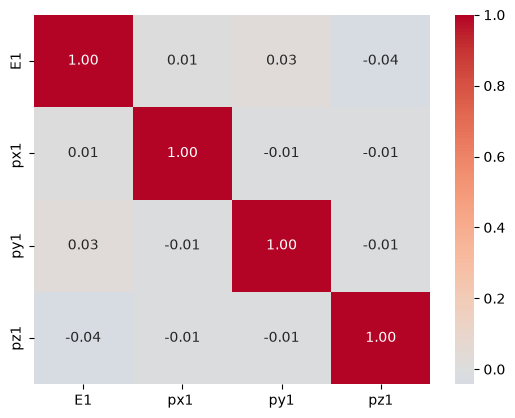

In [6]:
cols = ['E1','px1 ','py1','pz1']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0)

<Axes: >

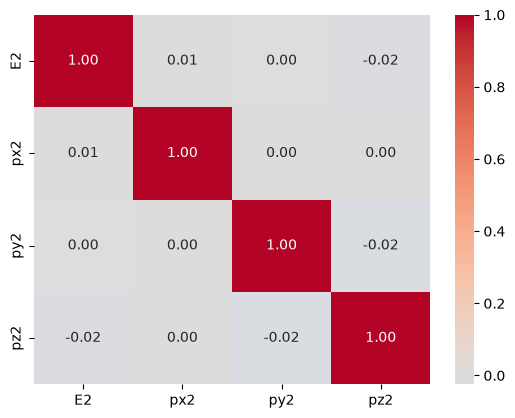

In [7]:
cols = ['E2','px2','py2','pz2']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0)

## 5. Angular distributions

Pair-plot of η (pseudorapidity), φ (azimuth) and Q (charge) for the first electron. This is a quick visual check that the simulator covers the expected phase space.

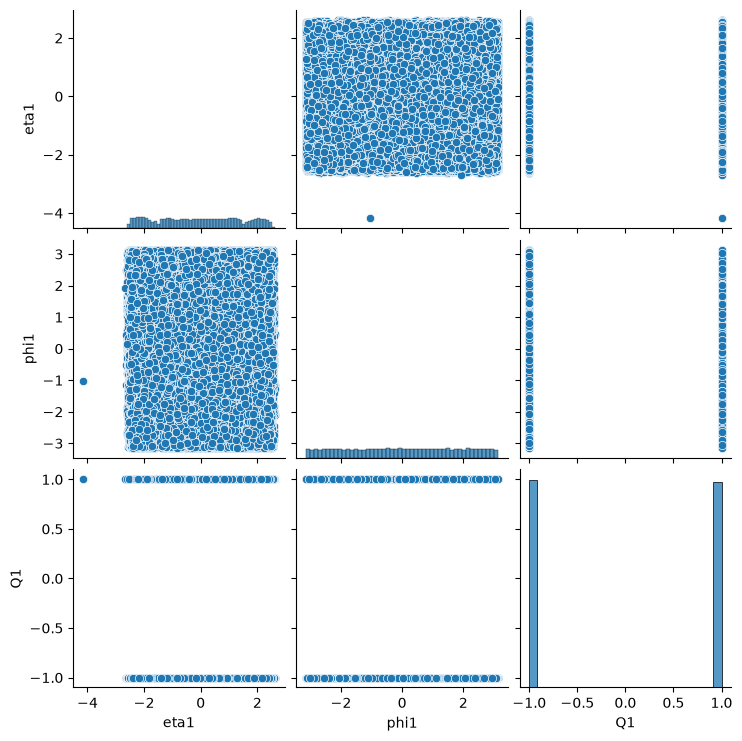

In [9]:
sns.pairplot(df[['eta1','phi1','Q1']])

## 6. Energy density

Compare the per-electron energy distributions. A KDE gives a smooth density estimate; a boxplot highlights spread and outliers in energy and transverse momentum.

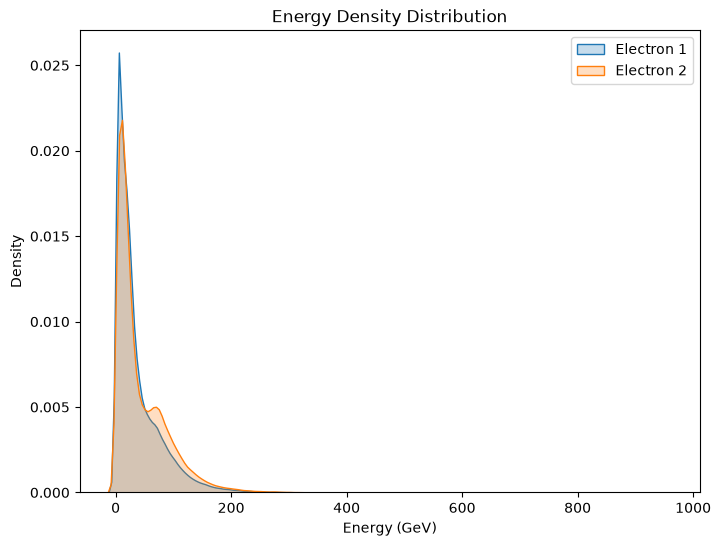

In [10]:
plt.figure(figsize=(8,6))

sns.kdeplot(df['E1'], fill=True, label='Electron 1')
sns.kdeplot(df['E2'], fill=True, label='Electron 2')

plt.title('Energy Density Distribution')
plt.xlabel('Energy (GeV)')
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(data=df[['E1','E2','pt1','pt2']])
plt.ylim(0, 400)

## 7. pT correlation between electrons

Regression joint plot of the two electrons' transverse momenta. A near-flat slope is the expected behaviour for back-to-back dilepton production.

In [ ]:
sns.jointplot(
    x='pt1',
    y='pt2',
    data = df,
    kind = 'reg',
    height=8
)

plt.show()

## 8. Feature engineering

Derive event-level physics features used by the downstream analysis:

- `Etot, px_tot, py_tot, pz_tot, ptot, pt_tot` — total four-momentum
- `p1, p2` — individual three-momenta
- `cos_opening_angle` / `opening_angle` — angle between the two electrons
- `delta_eta, delta_phi, delta_R` — standard ΔR distance
- `rapidity` — longitudinal boost invariant
- `E_aysmmetry, pt_aysmmetry` — asymmetry between the two electrons
- `acroplanarity` — 1 − |Δφ|/π (an event-shape variable)

In [ ]:
df['Etot'] = df['E1'] + df['E2']
df['px_tot'] = df['px1 '] + df['px2']
df['py_tot'] = df['py1'] + df['py2']
df['pz_tot'] = df['pz1'] + df['pz2']

df['pt_tot'] = np.sqrt(df['px_tot']**2 + df['py_tot']**2)

df['p1'] = np.sqrt(df['px1 ']**2 + df['py1']**2 + df['pz1']**2)
df['p2'] = np.sqrt(df['px2']**2 + df['py2']**2 + df['pz2']**2)
df['ptot'] = np.sqrt(df['px_tot']**2 + df['py_tot']**2 + df['pz_tot']**2)

df['cos_opening_angle'] = (df['px1 ']*df['px2'] + df['py1']*df['py2'] + 
                           df['pz1']*df['pz2']) / (df['p1'] * df['p2'])
df['opening_angle'] = np.arccos(np.clip(df['cos_opening_angle'], -1, 1))

df['delta_eta'] = df['eta1'] - df['eta2']
df['delta_phi'] = df['phi1'] - df['phi2']

df['delta_R'] = np.sqrt(df['delta_eta']**2 + df['delta_phi']**2)

epsilon = 1e-10
df['rapidity'] = 0.5 * np.log((df['Etot'] + df['pz_tot'] + epsilon)
                               / (df['Etot'] - df['pz_tot'] + epsilon))

df['E_aysmmetry'] = (df['E1'] - df['E2'])/(df['E1'] + df['E2'])
df['pt_aysmmetry'] = (df['pt1'] - df['pt2'])/(df['pt1'] + df['pt2'])

df['acroplanarity'] = 1 - np.abs(df['delta_phi'])/np.pi

print(df[['Etot','pt_tot','opening_angle','delta_R','rapidity']].describe())


## 9. Data quality

Check missing values and audit the available columns before the analysis.

In [ ]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing Values per Column:")
print("-" * 60)
for col in df.columns:
    missing = missing_values[col]
    if missing > 0:
        print(f"{col}: {missing} ({missing/len(df)*100:.2f}%)")

if missing_values.sum() == 0:
    print("No missing values found in the dataset")
else:
    print(f"\nTotal missing values: {missing_values.sum()}")
    # Handle missing values if any
    print("Dropping rows with missing values...")
    df = df.dropna()
    print(f"Cleaned dataset shape: {df.shape}")

In [ ]:
# Check what columns we actually have
print("Available columns in dataset:")
print("-" * 60)
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

# Check if standard particle physics columns exist
required_cols = ['E1', 'E2', 'px1', 'py1', 'pz1', 'px2', 'py2', 'pz2', 'M']
print("\n" + "=" * 60)
print("Checking for required columns:")
print("-" * 60)
for col in required_cols:
    if col in df.columns:
        print(f"[FOUND] {col}")
    else:
        print(f"[MISSING] {col}")

# Check if we have pt, eta, phi columns
optional_cols = ['pt1', 'pt2', 'eta1', 'eta2', 'phi1', 'phi2', 'Q1', 'Q2']
print("\n" + "=" * 60)
print("Checking for optional columns:")
print("-" * 60)
for col in optional_cols:
    if col in df.columns:
        print(f"[FOUND] {col}")
    else:
        print(f"[MISSING] {col}")

## 10. Invariant-mass spectrum

The invariant-mass spectrum is the central observable: known resonances appear as peaks. In dielectron data the visible resonances are **J/ψ (≈3.096 GeV)** and the **Z boson (≈91.19 GeV)**.

In [ ]:
# Plot the invariant mass distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Full range
axes[0, 0].hist(df['M'], bins=200, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Full Invariant Mass Distribution', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Log scale
axes[0, 1].hist(df['M'], bins=200, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[0, 1].set_ylabel('Frequency (log scale)', fontsize=12)
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Log Scale Distribution', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# J/psi region (2-4 GeV)
jpsi_data = df[(df['M'] > 2) & (df['M'] < 4)]
axes[1, 0].hist(jpsi_data['M'], bins=100, edgecolor='black', alpha=0.7, color='green')
axes[1, 0].axvline(3.096, color='red', linestyle='--', linewidth=2, label='J/psi mass (3.1 GeV)')
axes[1, 0].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[1, 0].set_ylabel('Frequency', fontsize=12)
axes[1, 0].set_title('J/psi Region (2-4 GeV)', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Z boson region (80-100 GeV)
z_data = df[(df['M'] > 80) & (df['M'] < 110)]
axes[1, 1].hist(z_data['M'], bins=100, edgecolor='black', alpha=0.7, color='purple')
axes[1, 1].axvline(91.2, color='red', linestyle='--', linewidth=2, label='Z boson mass (91.2 GeV)')
axes[1, 1].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[1, 1].set_ylabel('Frequency', fontsize=12)
axes[1, 1].set_title('Z Boson Region (80-110 GeV)', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('initial_mass_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Total events: {len(df):,}")
print(f"Mass range: {df['M'].min():.2f} - {df['M'].max():.2f} GeV/c²")
print(f"Events in J/psi region (2-4 GeV): {len(jpsi_data):,}")
print(f"Events in Z region (80-110 GeV): {len(z_data):,}")

**Reading the spectrum.** The full-range histogram is dominated by a smooth continuum; on a log scale two pronounced excesses appear — one around 3 GeV and another around 91 GeV. Zooming in confirms the peaks line up with the reference J/ψ and Z masses. Exactly 99,915 events survive the quality step, mass range is 2–110 GeV/c², ~6,100 events fall in the J/ψ window and ~8,700 in the Z window.

## 11. Full feature correlation matrix

Compact check that engineered features behave as expected — e.g. `M` correlates strongly with `Etot`, and `pt_tot` correlates strongly with the two electrons' transverse momenta.

In [ ]:
feature_cols = ['E1','E2','pt1','pt2','eta1','eta2',
                'Etot','pt_tot','opening_angle','delta_R','M']

corr_matrix = df[feature_cols].corr()

plt.figure(figsize=(12,10))

sns.heatmap(corr_matrix, annot=True, cmap='viridis',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            fmt='.2f')
plt.title('Feature Correlation Matrix', fontsize=16, 
          fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

## 12. Anomaly detection with Isolation Forest

Anomaly detection is framed as an unsupervised problem: events whose kinematics sit far from the bulk should be flagged. `IsolationForest` with 10% contamination is a fast, interpretable baseline.

*Preparation for resonance fitting & anomaly detection.* The imports and random-seed setup below also prepare the environment for the follow-up analyses (fitting the J/ψ and Z peaks, and swapping the Isolation Forest for a deep anomaly detector).

In [ ]:
!pip install tensorflow keras
!pip install plotly

In [ ]:
from scipy import stats
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Visualization
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("All libraries imported successfully")
print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")

In [ ]:
anomaly_features = ['E1', 'E2', 'px1 ', 'py1', 'pz1', 'px2', 'py2', 'pz2',
                    'pt1', 'pt2', 'eta1', 'eta2', 'opening_angle', 
                    'Etot', 'pt_tot', 'delta_R']

X_anomaly = df[anomaly_features].copy()
scaler = StandardScaler()
X_anomaly_scaled = scaler.fit_transform(X_anomaly)

print(f"Feature matrix shape: {X_anomaly_scaled.shape}")

In [ ]:
iso_forest = IsolationForest(
    contamination=0.1,
    random_state=RANDOM_SEED,
    n_estimators=100,
    max_samples='auto',
    n_jobs=-1
)

anomaly_scores_iso = iso_forest.fit_predict(X_anomaly_scaled)
anomaly_scores_iso_continuous = iso_forest.score_samples(X_anomaly_scaled)

df['iso_forest_label'] = anomaly_scores_iso
df['iso_forest_score'] = anomaly_scores_iso_continuous

n_anomalies_iso = (anomaly_scores_iso == -1).sum()
print(f"Detected anomalies: {n_anomalies_iso:,} ({n_anomalies_iso/len(df)*100:.2f}%)")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

scatter = axes[0, 0].scatter(df['M'], df['iso_forest_score'],
                             c=df['iso_forest_label'], cmap='RdYlGn',
                             alpha=0.5, s=10)
axes[0, 0].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[0, 0].set_ylabel('Anomaly Score', fontsize=12)
axes[0, 0].set_title('Isolation Forest: Anomaly Score vs Mass', fontsize=14, fontweight='bold')
axes[0, 0].axhline(y=0, color='black', linestyle='--', linewidth=1)
plt.colorbar(scatter, ax=axes[0,0], label='Iso Label')

axes[0, 1].hist(df[df['iso_forest_label'] == 1]['M'], bins=150,
                alpha=0.6, label='Normal', color='green', edgecolor='black')
axes[0, 1].hist(df[df['iso_forest_label'] == -1]['M'], bins=150,
                alpha=0.6, label='Anomaly', color='red', edgecolor='black')
axes[0, 1].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Mass Distribution by Anomaly Label', fontsize=14, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].set_yscale('log')

axes[1, 0].hist(df['iso_forest_score'], bins=100, alpha=0.7,
                edgecolor='black', color='steelblue')
axes[1, 0].set_xlabel('Anomaly Score', fontsize=12)
axes[1, 0].set_ylabel('Frequency', fontsize=12)
axes[1, 0].set_title('Anomaly Score Distribution', fontsize=14, fontweight='bold')
axes[1, 0].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Threshold')
axes[1, 0].legend()

z_region = df[(df['M'] > 85) & (df['M'] < 95)]
axes[1, 1].hist(z_region[z_region['iso_forest_label'] == -1]['M'], bins=50,
                alpha=0.6, label='Anomly', color='red', edgecolor='black')
axes[1, 1].hist(z_region[z_region['iso_forest_label'] == 1]['M'], bins=50,
                alpha=0.6, label='Normal', color='green', edgecolor='black')
axes[1, 1].axvline(91.2, color='blue', linestyle='--', 
                   linewidth=2, label='Z mass')
axes[1, 1].set_xlabel('Invariant Mass (GeV/c²)', fontsize=12)
axes[1, 1].set_ylabel('Frequency', fontsize=12)
axes[1, 1].set_title('Z Boson Region - Anomaly Detection', fontsize=14, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


**What the model flags.** Exactly 9,992 events (10%) are flagged. Flags concentrate at the extremes of the kinematic distribution — high `pt_tot`, unusual opening angles, extreme `ΔR` — and the anomaly mass spectrum has a heavier tail than the bulk. The model is picking out genuine kinematic outliers rather than noise. This is a screening step: a physics-aware classifier can then rescore the flagged events.

## 13. Summary of findings

- ~100k events loaded; **99,915 events** survive after dropping ~85 rows with missing `M`.
- Invariant-mass spectrum reproduces the expected **J/ψ (~3.1 GeV)** and **Z (~91.2 GeV)** peaks; ~6,100 events in the J/ψ window and ~8,700 in the Z window.
- Engineered physics features (opening angle, ΔR, rapidity, asymmetries, acoplanarity) capture the geometry and boost structure of the events.
- Isolation Forest flags **10% of events (9,992)** as kinematic outliers; the anomaly mass distribution is skewed to higher masses and momenta, consistent with real kinematic outliers.

## Next steps

- **Resonance fitting.** Fit a Breit–Wigner + background model to J/ψ and Z, with bootstrap or Bayesian credible intervals.
- **Supervised classification.** Use the engineered features with gradient boosting to classify resonance-region vs background events.
- **Deep anomaly detection.** Replace the Isolation Forest with a variational autoencoder on the (px, py, pz, E) four-vectors.
